# Team29 | Classification model training (retrain and export)

This notebook rebuilds the normal/abnormal classifier that the web app serves: a text model
(TF-IDF + logistic regression on the clinical indication), ResNet50 and DenseNet121 image
models, and a late fusion of the two. It runs the same Python functions as
`scripts/run_team_classification.py`, step by step, and exports a checksummed bundle that the
FastAPI service and the Streamlit app load.

**Dataset.** Indiana University chest X-rays (OpenI), Kaggle copy by raddar:
<https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university> (about 14 GB).

**Hardware.** Written for one CUDA GPU with 6 GB (tested on an RTX 3060 Laptop GPU). Training
uses batch size 8, mixed precision and at most 18 epochs per CNN with early stopping. CPU works
but is very slow.

**Re-running.** Every step skips work that is already saved under
`artifacts/team_classification/`. An interrupted CNN resumes from its best checkpoint. The final
test runs once and then locks; delete that folder to start a clean experiment.

**Why retrain.** The original trained bundle (`0.2.0-team29-47e281fc`) was not available for the
deployment, so this run reproduces it with the same code, data, split and settings. GPU training
is not bit-for-bit repeatable, so the numbers are close to the original but not identical. The
export gets its own version name for that reason.

## 1 | Setup

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
# Same thread and backend settings as scripts/run_team_classification.py.
os.environ.update(
    OPENBLAS_NUM_THREADS="1",
    OMP_NUM_THREADS="2",
    MKL_NUM_THREADS="2",
    TORCH_CUDNN_V8_API_DISABLED="1",
    MLFLOW_DISABLE_AGENT_HINT="1",
)
os.environ.setdefault("TORCH_HOME", str(ROOT / "artifacts/torch-cache"))
os.environ.setdefault("KAGGLEHUB_CACHE", str(ROOT / "data/.cache"))
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]

import pandas as pd
import torch

torch.set_num_threads(2)
OUTPUT = ROOT / "artifacts/team_classification"
print("Repository:", ROOT.name)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU is very slow)")

Repository: Explainable-Multimodal-Pulmonary-Diagnostics
PyTorch: 2.13.0+cu130


GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 2 | Dataset

Downloads the Kaggle copy with KaggleHub. The download resumes after a dropped connection, and
this cell retries up to 30 times. The public dataset did not ask for a Kaggle login here; if it
does for you, sign in with KaggleHub first and never save credentials in the repository.

In [2]:
DATASET = "raddar/chest-xrays-indiana-university"
saved = ROOT / "data/download_manifest.json"
if saved.exists():
    data_root = Path(json.loads(saved.read_text())["downloaded_path"])
else:
    import kagglehub

    for attempt in range(1, 31):
        try:
            data_root = Path(kagglehub.dataset_download(DATASET))
            break
        except Exception as error:
            print(f"Attempt {attempt} failed ({type(error).__name__}); retrying in 20 s")
            time.sleep(20)
    else:
        raise RuntimeError("The dataset download failed 30 times")
print("Source: https://www.kaggle.com/datasets/" + DATASET)
print("CSV files:", sorted(p.name for p in data_root.rglob("*.csv")))
print("PNG images:", sum(1 for _ in data_root.rglob("*.png")))

Source: https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university
CSV files: ['indiana_projections.csv', 'indiana_reports.csv']
PNG images: 7470


## 3 | Labels, pairing and split

Builds the strict normal/abnormal label from the structured annotations, pairs each study with
its frontal and lateral image, letterboxes every image to 384 px, and makes a seeded study-level
split. Exact duplicate images are kept inside one split. The split fingerprint is compared with
the cohort the original model used.

In [3]:
from pulmonary.common import file_hash
from pulmonary.team_classification import finalize, prepare, train_text, train_vision

if (OUTPUT / "cohort_manifest.json").exists():
    print("Prepared earlier; reusing", OUTPUT.relative_to(ROOT))
else:
    prepare(data_root, OUTPUT)
cohort = json.loads((OUTPUT / "cohort_manifest.json").read_text())
COHORT = file_hash(OUTPUT / "cohort_manifest.json")
OFFICIAL_COHORT = "47e281fc13b74f0c498e0f6fe2896e50bae9e147a49ea0c795b3c750ed369b21"
display(pd.DataFrame({"studies": cohort["study_counts"], "images": cohort["image_counts"]}))
print("Cohort fingerprint:", COHORT[:16])
print("Same split as the original model:", COHORT == OFFICIAL_COHORT)

Prepared 250/2371 studies


Prepared 500/2371 studies


Prepared 750/2371 studies


Prepared 1000/2371 studies


Prepared 1250/2371 studies


...

Prepared 2000/2371 studies


Prepared 2250/2371 studies


{
  "preprocessing": "team29-gray-lanczos-letterbox384-imagenet-v1",
  "seed": 42,
  "strict_downgrades": 57,
  "duplicate_image_rows": 0,
  "cross_split_duplicate_components": 0,
  "split_changed_for_duplicates": false,
  "patient_independence_verified": false,
  "previous_project_test_already_seen": true,
  "study_counts": {
    "train": 1660,
    "test": 356,
    "val": 355
  },
  "image_counts": {
    "train": 3179,
    "val": 683,
    "test": 681
  },
  "csv_sha256": {
    "reports": "cd7257716f7be4aaf46e55a9ea266b69095372a2f23dc0e19e32a95b0f02e2e6",
    "projections": "7af9c8a6b4f8ae695c654ecd4208edd193a37892a5607b7cb9e609dc997e6b7a"
  },
  "manifest_sha256": {
    "studies": "a673a60197faf6722bdbfe881f0db935c7266b5f1e375b8bd2ac75b1c91a5a5d",
    "images": "166a58da7ced92b459e2f26b535777a49289c17f5aed541f9a76364aa5a3da6c"
  }
}


,studies,images
train,1660,3179
test,356,681
val,355,683


Cohort fingerprint: 47e281fc13b74f0c
Same split as the original model: True


## 4 | Text model

TF-IDF and metadata features from the clinical indication and comparison, with logistic
regression. The C value and class weighting are chosen on validation ROC-AUC.

In [4]:
if (OUTPUT / "text_model.joblib").exists():
    print("Text model trained earlier; reusing")
else:
    train_text(OUTPUT)
print(json.loads((OUTPUT / "text_selection.json").read_text())["validation_auc"])
display(pd.read_csv(OUTPUT / "text_search.csv").sort_values("validation_auc", ascending=False).head(5))

TF-IDF validation AUC: 0.6726


0.6725625121147508


,C,class_weight,validation_auc
4,0.3,NaN,0.672563
5,0.3,balanced,0.671658
2,0.1,NaN,0.665714
3,0.1,balanced,0.665617
6,1.0,NaN,0.662354


## 5 | Image models

ImageNet-pretrained ResNet50 and DenseNet121. Three epochs train only the head, then the last
blocks are unfrozen. Early stopping watches validation loss. Each epoch prints its losses and
time; checkpoints are saved as training goes.

In [5]:
train_vision(OUTPUT, "resnet50")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to D:\Projects\NadeenSamsungDeployment\Explainable-Multimodal-Pulmonary-Diagnostics\artifacts\torch-cache\hub\checkpoints\resnet50-11ad3fa6.pth


  0%|          | 0.00/97.8M [00:00<?, ?B/s]

  0%|          | 256k/97.8M [00:00<00:44, 2.31MB/s]

  1%|          | 768k/97.8M [00:00<00:26, 3.80MB/s]

  1%|▏         | 1.38M/97.8M [00:00<00:20, 4.93MB/s]

...

resnet50 head epoch 2/18 train_loss=0.63439 val_loss=0.61801 seconds=30.1


resnet50 head epoch 3/18 train_loss=0.61512 val_loss=0.60572 seconds=29.4


resnet50 finetune epoch 4/18 train_loss=0.55873 val_loss=0.54606 seconds=46.5


resnet50 finetune epoch 5/18 train_loss=0.50472 val_loss=0.55716 seconds=41.5


resnet50 finetune epoch 6/18 train_loss=0.46845 val_loss=0.59966 seconds=41.1


In [6]:
train_vision(OUTPUT, "densenet121")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to D:\Projects\NadeenSamsungDeployment\Explainable-Multimodal-Pulmonary-Diagnostics\artifacts\torch-cache\hub\checkpoints\densenet121-a639ec97.pth


  0%|          | 0.00/30.8M [00:00<?, ?B/s]

  0%|          | 128k/30.8M [00:00<01:07, 474kB/s]

  1%|          | 256k/30.8M [00:00<00:45, 708kB/s]

  2%|▏         | 512k/30.8M [00:00<00:26, 1.21MB/s]

...

densenet121 head epoch 3/18 train_loss=0.62616 val_loss=0.60649 seconds=32.2


densenet121 finetune epoch 4/18 train_loss=0.58954 val_loss=0.53440 seconds=49.5


densenet121 finetune epoch 5/18 train_loss=0.52569 val_loss=0.51198 seconds=48.4


densenet121 finetune epoch 6/18 train_loss=0.49342 val_loss=0.52260 seconds=50.3


densenet121 finetune epoch 7/18 train_loss=0.48511 val_loss=0.57494 seconds=49.9


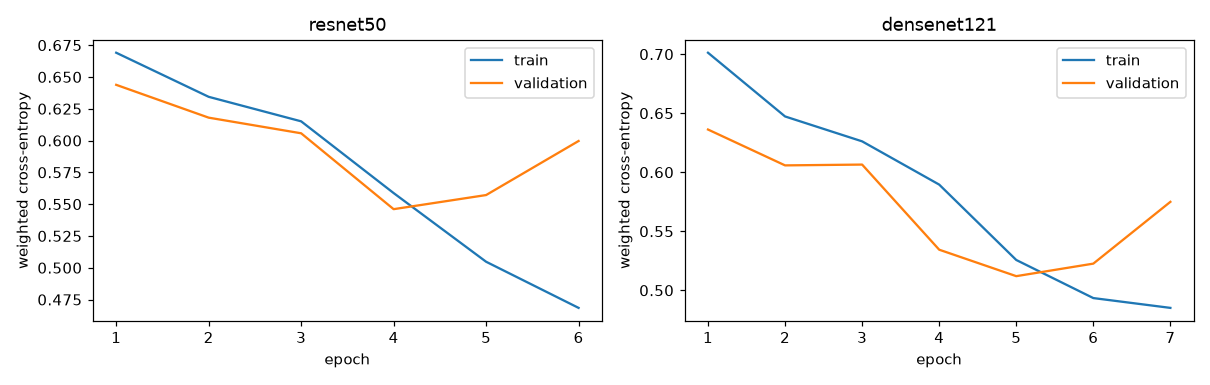

In [7]:
import io

import matplotlib.pyplot as plt
from IPython.display import Image as ShowImage

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis, name in zip(axes, ["resnet50", "densenet121"], strict=True):
    history = pd.read_csv(OUTPUT / f"{name}_history.csv")
    axis.plot(history.epoch, history.train_loss, label="train")
    axis.plot(history.epoch, history.val_loss, label="validation")
    axis.set(title=name, xlabel="epoch", ylabel="weighted cross-entropy")
    axis.legend()
fig.tight_layout()
# The repo switches matplotlib to a non-interactive backend, so render the PNG directly.
buffer = io.BytesIO()
fig.savefig(buffer, format="png", dpi=110)
plt.close(fig)
display(ShowImage(buffer.getvalue()))

## 6 | Fusion and the single test evaluation

The fusion weight and every decision threshold are chosen on validation only and saved before
the test set is scored. The test then runs once and writes a lock file. The table compares this
run with the original model's saved results (`reports/evidence/team29/ablation_results.csv`).

In [8]:
if (OUTPUT / "test_evaluation_lock.json").exists():
    print("Test already evaluated; showing saved results")
else:
    finalize(OUTPUT)
new = pd.read_csv(OUTPUT / "ablation_results.csv").set_index("model")
old = pd.read_csv(ROOT / "reports/evidence/team29/ablation_results.csv").set_index("model")
comparison = pd.concat(
    {"this run": new[["accuracy", "f1", "roc_auc", "threshold"]],
     "original": old[["accuracy", "f1", "roc_auc", "threshold"]]},
    axis=1,
).round(4)
display(comparison)
print("Fusion image weight:", json.loads((OUTPUT / "selection.json").read_text())["image_weight"])

            model  accuracy       f1  roc_auc  threshold  studies
        text_only  0.662921 0.565217 0.720297       0.49      356
         resnet50  0.775281 0.738562 0.855278       0.34      356
      densenet121  0.775281 0.718310 0.863894       0.44      356
   image_ensemble  0.792135 0.762821 0.866851       0.33      356
multimodal_fusion  0.808989 0.782051 0.873634       0.35      356


this run                           original                  \
                  accuracy      f1 roc_auc threshold accuracy      f1 roc_auc   
model                                                                           
text_only           0.6629  0.5652  0.7203      0.49   0.6629  0.5652  0.7203   
resnet50            0.7753  0.7386  0.8553      0.34   0.8230  0.7961  0.8784   
densenet121         0.7753  0.7183  0.8639      0.44   0.7921  0.7658  0.8644   
image_ensemble      0.7921  0.7628  0.8669      0.33   0.8174  0.7855  0.8757   
multimodal_fusion   0.8090  0.7821  0.8736      0.35   0.8287  0.7918  0.8816   

                             
                  threshold  
model                        
text_only              0.49  
resnet50               0.44  
densenet121            0.46  
image_ensemble         0.48  
multimodal_fusion      0.49

Fusion image weight: 0.75


## 7 | Export the serving bundle

Writes `artifacts/team_bundle/` (manifest with SHA-256 for every file) and zips it in the same
layout as the original `dist/SIC_0.2.0-team29_model_bundle.zip`. The Streamlit app downloads this
ZIP from a GitHub release and loads it only if its SHA-256 matches the value pinned in
`deploy/streamlit/streamlit_app.py`.

In [9]:
from zipfile import ZIP_DEFLATED, ZipFile

VERSION = "0.2.1-team29-" + COHORT[:8]
BUNDLE = ROOT / "artifacts/team_bundle"
if not (BUNDLE / "manifest.json").exists():
    subprocess.run(
        [sys.executable, "scripts/export_team_bundle.py", "--model-version", VERSION],
        check=True, capture_output=True,
    )
manifest = json.loads((BUNDLE / "manifest.json").read_text())
ARCHIVE = ROOT / "dist/SIC_0.2.1-team29_model_bundle.zip"
ARCHIVE.parent.mkdir(exist_ok=True)
if not ARCHIVE.exists():
    with ZipFile(ARCHIVE, "w", ZIP_DEFLATED) as archive:
        for name in ["manifest.json", *manifest["files"]]:
            archive.write(BUNDLE / name, "artifacts/team_bundle/" + name)
        archive.writestr(
            "MODEL_BUNDLE_README.txt",
            "Version: " + manifest["model_version"]
            + "\nRetrained with notebooks/Team29_Classification_Training.ipynb."
            + "\nChecksums are verified when the service starts.\n",
        )
print("Model version:", manifest["model_version"])
print("Threshold:", round(manifest["threshold"], 3), "| image weight:", manifest["image_weight"])
print("Bundle ZIP:", ARCHIVE.relative_to(ROOT), f"{ARCHIVE.stat().st_size / 1e6:.1f} MB")
print("SHA-256:", hashlib.sha256(ARCHIVE.read_bytes()).hexdigest())

Model version: 0.2.1-team29-47e281fc
Threshold: 0.35 | image weight: 0.75
Bundle ZIP: dist\SIC_0.2.1-team29_model_bundle.zip 114.2 MB
SHA-256: b6a0fda4d3359afe0b0b5c95dde0532fcc016394c622a2f9f17088127b9c3f95


## 8 | Check the bundle in the app

Loads the exported bundle through the same in-process service the Streamlit app uses and runs
the three demo X-rays. The original model's scores are shown next to the new ones.

In [10]:
os.environ["MODEL_BUNDLE"] = str(BUNDLE)
from app.inprocess import InProcessService

service = InProcessService()
print(service.get("/health").json())
rows = []
for case in pd.read_csv(ROOT / "demo_images/demo_cases.csv", keep_default_na=False).itertuples():
    image = ROOT / "demo_images" / case.filename
    response = service.post(
        "/explain",
        files={"image": (image.name, image.read_bytes(), "image/png")},
        data={"indication": case.indication, "comparison": case.comparison},
    )
    body = response.json()
    rows.append({
        "case": case.category,
        "weak label": case.weak_label,
        "original score": round(case.probability, 3),
        "new score": round(body["prediction"]["probability"], 3),
        "new class": body["predicted_class"],
        "Grad-CAM region": body["gradcam_region"],
    })
display(pd.DataFrame(rows))

{'status': 'ready', 'model_version': '0.2.1-team29-47e281fc'}


,case,weak label,original score,new score,new class,Grad-CAM region
0,normal,normal,0.213,0.160,Normal,upper image-right image region (patient latera...
1,abnormal,abnormal,0.908,0.905,Abnormal,diffuse across the radiograph (no dominant ver...
2,false_prediction,normal,0.711,0.532,Abnormal,lower central image region (patient laterality...
